In [9]:

import geopandas as gpd
import numpy as np
import pandas as pd
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt
import contextily

from sklearn.metrics import classification_report

import sys
sys.path.append('..')
from model.dataset import LABEL_MAPPING

CLASS_INDICES = [value for key, value in LABEL_MAPPING.items()]
CLASS_NAMES = [key for key in LABEL_MAPPING.keys()]


In [10]:

df = pd.read_csv('../data/labels/dataset_v3/labels.csv')

df['geometry'] = gpd.GeoSeries.from_wkt(df['geometry'])

gdf = gpd.GeoDataFrame(df)

gdf_train = gdf.loc[gdf.split == 'train']

gdf_val = gdf.loc[gdf.split == 'val']

In [11]:
def get_kde(df, **kwargs):

    # Step 2: Extract x and y coordinates
    x = df.geometry.x.values
    y = df.geometry.y.values
    data = np.vstack([x, y])
    #print(kwargs)
    # Step 3: Compute KDE
    if kwargs:
        kde = gaussian_kde(data, **kwargs)
    else:
        kde = gaussian_kde(data)
    
    return kde

In [12]:
def _plot_kde(kde, xmin, xmax, ymin, ymax, grid_size=100):
    """
    Plot a 2D KDE using Matplotlib.

    Args:
    kde: gaussian_kde object.
    xmin, xmax, ymin, ymax: float, boundaries for the plot.
    grid_size: int, size of the grid for the KDE evaluation.

    Returns:
    fig, ax: matplotlib Figure and Axes objects.
    """
    # Create a grid
    xgrid = np.linspace(xmin, xmax, grid_size)
    ygrid = np.linspace(ymin, ymax, grid_size)
    X, Y = np.meshgrid(xgrid, ygrid)

    # Evaluate the KDE on the grid
    positions = np.vstack([X.ravel(), Y.ravel()])
    Z = np.reshape(kde(positions).T, X.shape)

    # Plot the density
    fig, ax = plt.subplots()
    ax.imshow(np.flipud(Z), cmap='viridis', extent=[xmin, xmax, ymin, ymax])
    ax.set_xlim([xmin, xmax])
    ax.set_ylim([ymin, ymax])
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    plt.title('2D Gaussian KDE')
    plt.show()
    
    return fig, ax

In [13]:
def plot_kde_per_class(gdf, grid_size):
    
    xmin = gdf.geometry.x.min()
    xmax = gdf.geometry.x.max()
    ymin = gdf.geometry.y.min()
    ymax = gdf.geometry.y.max()

    # Create a grid
    xgrid = np.linspace(xmin, xmax, grid_size)
    ygrid = np.linspace(ymin, ymax, grid_size)
    X, Y = np.meshgrid(xgrid, ygrid)
    positions = np.vstack([X.ravel(), Y.ravel()])

    classes = gdf.driver.unique()
    
    # Set up the figure and axes    
    fig, axs = plt.subplots(len(classes), 1, figsize=(16, 4 * len(classes)))
    
    for i, _cls in enumerate(classes):
        gdf_class = gdf.loc[gdf.driver == _cls]

        class_kde = get_kde(gdf_class)
        #kde_per_class[_cls] = class_kde
    
        # Evaluate the KDE on the grid
        Z = np.reshape(class_kde(positions).T, X.shape)

        # Plot the density
        ax = axs[i]  # Get the i-th subplot
        cax = ax.imshow(Z, cmap='viridis', extent=[xmin, xmax, ymin, ymax])
        ax.set_xlim([xmin, xmax])
        ax.set_ylim([ymin, ymax])
        ax.set_xlabel('lon')
        ax.set_ylabel('lat')
        ax.set_title(f'{_cls}')
        #fig.colorbar(cax, ax=ax)  # Add a colorbar to each subplot

    plt.tight_layout()
    plt.show()

In [14]:
def plot_kde(df, xmin, xmax, ymin, ymax, **kwargs):
    


    kde = get_kde(df, **kwargs)
    
    _plot_kde(kde, xmin, xmax, ymin, ymax, grid_size=100)
    
    

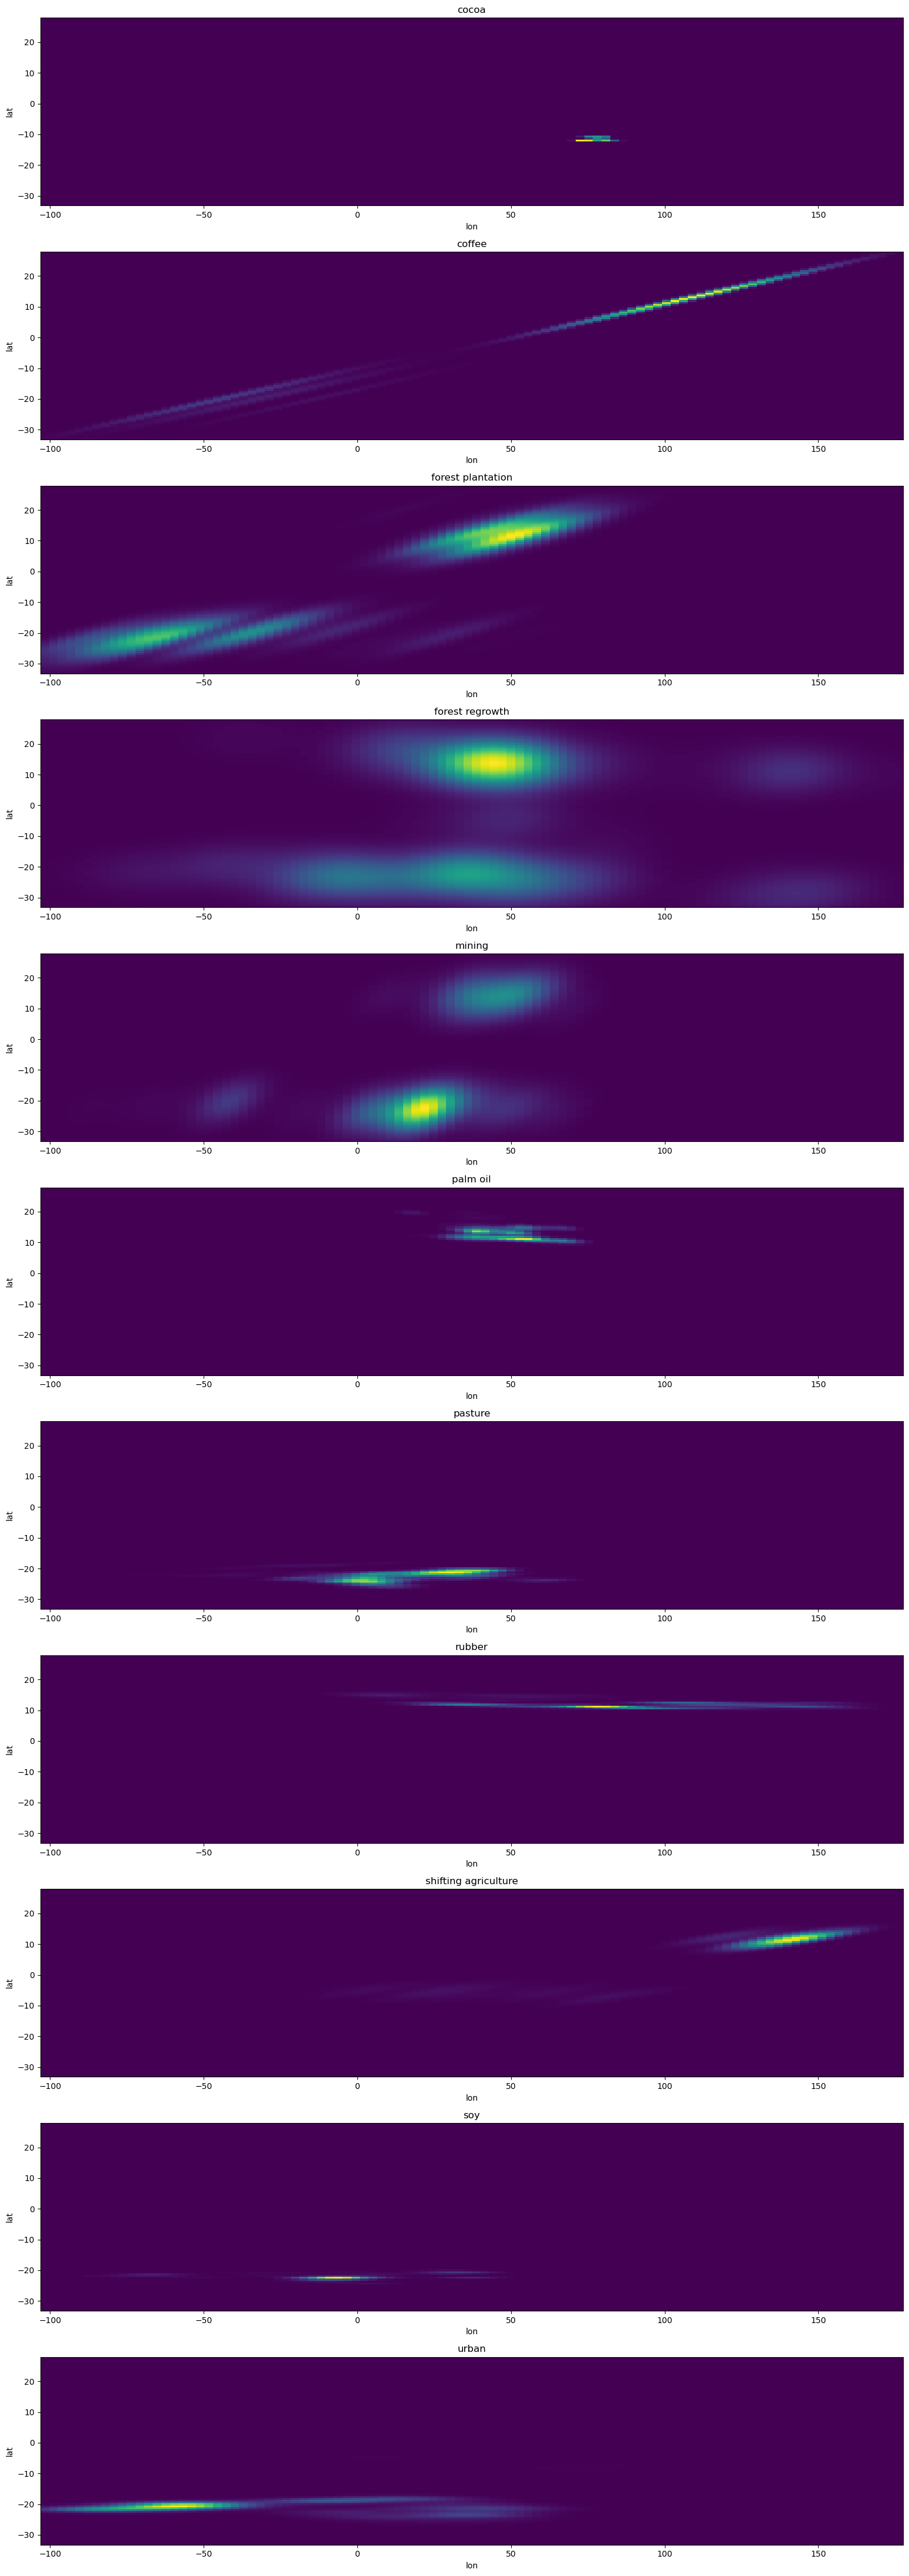

In [37]:
plot_kde_per_class(gdf_train, grid_size=100)

## Show the problem

<Axes: >

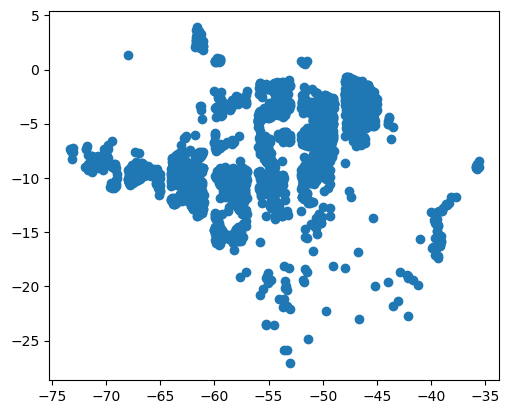

In [7]:
gdf_train.loc[gdf_train.driver == 'pasture'].plot()

In [8]:
pasture_gdf = gdf_train.loc[gdf_train.driver == 'pasture']

In [9]:
xmin = pasture_gdf.geometry.x.min()
xmax = pasture_gdf.geometry.x.max()
ymin = pasture_gdf.geometry.y.min()
ymax = pasture_gdf.geometry.y.max()

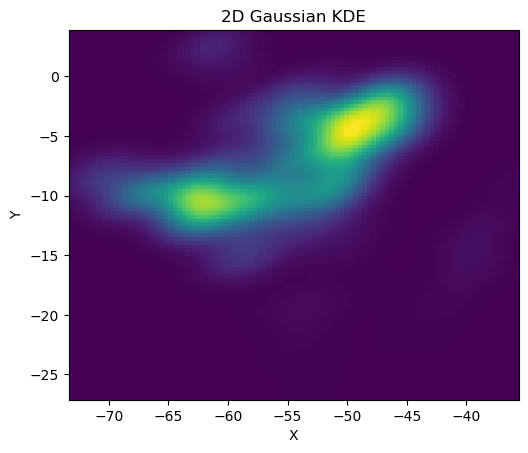

In [13]:
plot_kde(
    pasture_gdf,
    xmin, xmax, ymin, ymax,
    bw_method=0.3

)

In [103]:
xmin = gdf.geometry.x.min()
xmax = gdf.geometry.x.max()
ymin = gdf.geometry.y.min()
ymax = gdf.geometry.y.max()

In [62]:
print(xmin, xmax, ymin, ymax)

-103.21345260729805 177.6165907152284 -33.20240415635769 27.92017553844228


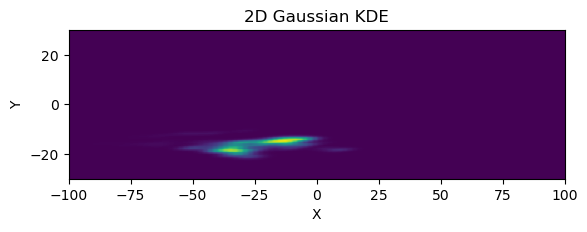

In [64]:
plot_kde(
    pasture_gdf,
    -100, , -30, 30
    
)

In [77]:
cocoa = gdf_train.loc[gdf_train.driver == 'cocoa']

<Axes: >

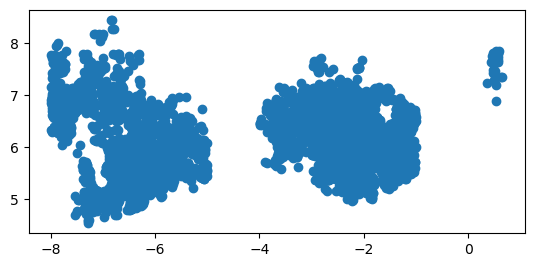

In [78]:
cocoa.plot()

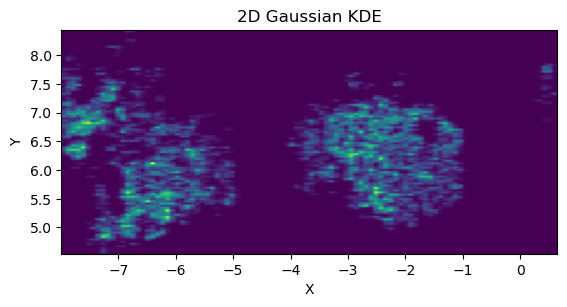

In [115]:
plot_kde(
    cocoa,
    cocoa.geometry.x.min(), cocoa.geometry.x.max(), cocoa.geometry.y.min(), cocoa.geometry.y.max(),
    bw_method=0.02

)

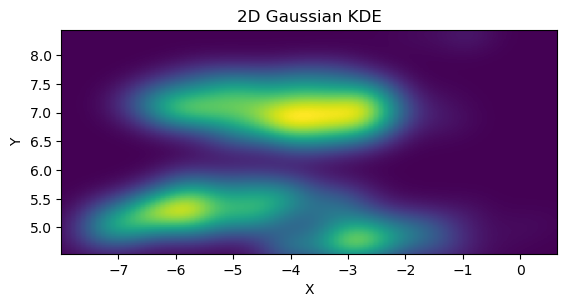

In [84]:
plot_kde(
    cocoa,
    cocoa.geometry.x.min(), cocoa.geometry.x.max(), cocoa.geometry.y.min(), cocoa.geometry.y.max(),

)

In [32]:
gdf_train.driver.unique()

array(['cocoa', 'coffee', 'forest plantation', 'forest regrowth',
       'mining', 'palm oil', 'pasture', 'rubber', 'shifting agriculture',
       'soy', 'urban'], dtype=object)

In [52]:
import numpy as np
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KernelDensity

best_bandwidths = {}


for _cls in gdf_train.driver.unique():

    df = gdf_train.loc[gdf_train.driver == _cls]

    x = df.geometry.x.values
    y = df.geometry.y.values
    data = np.vstack([x, y]).transpose()

    
    _min, _max = 0.1, 1
    
    steps = 5 
    
    print(_cls)
    
    for i in range(5):
        
        # Set up grid search parameters
        params = {
            'bandwidth': np.linspace(_min, _max, steps),
            #'bandwidth': [_min, _min*2, _min*3,  _min*4,  _min*5,  _min*6,  _min*7,  _min*8,  _min*9,  _min*10]
            }  

        grid = GridSearchCV(KernelDensity(kernel='gaussian'), params, cv=5)  # 5-fold cross-validation
        grid.fit(data)

        # Optimal bandwidth after cross-validation
        best_bandwidth = grid.best_estimator_.bandwidth
        print(best_bandwidth)

        _min, _max = best_bandwidth/5, best_bandwidth*5,
        steps += 5
        
    
    best_bandwidths[_cls] = best_bandwidth
        
        
    
    
    #print(f"Best bandwidth for class {_cls}: ", best_bandwidth)


cocoa
0.1
0.07333333333333333
0.03980952380952381
0.048190476190476186
0.048190476190476186
coffee
1.0
1.2666666666666666
1.5561904761904763
1.4906666666666668
1.4906666666666668
forest plantation
0.1
0.12666666666666665
0.11219047619047619
0.1358095238095238
0.1358095238095238
forest regrowth
0.55
0.6966666666666667
0.6170476190476191
0.5910666666666666
0.5910666666666666
mining
1.0
1.2666666666666666
1.5561904761904763
1.4906666666666668
1.4906666666666668
palm oil
0.1
0.12666666666666665
0.11219047619047619
0.1358095238095238
0.1358095238095238
pasture
0.325
0.23833333333333334
0.2928095238095238
0.28048070175438594
0.3365768421052631
rubber
0.325
0.23833333333333334
0.21109523809523809
0.25553634085213034
0.20442907268170427
shifting agriculture
1.0
5.0
23.285714285714285
22.305263157894736
22.305263157894736
soy
0.325
0.23833333333333334
0.21109523809523809
0.14887769423558897
0.17865323308270675
urban
1.0
5.0
9.571428571428571
9.16842105263158
9.16842105263158


In [ ]:
kde_per_class = {}


for _cls in gdf_train.driver.unique():

    df = gdf_train.loc[gdf_train.driver == _cls]

    x = df.geometry.x.values
    y = df.geometry.y.values
    data = np.vstack([x, y]).transpose()

    kde = KernelDensity(kernel='gaussian', bandwidth=best_bandwidths[_cls]).fit(data)
    
    kde_per_class[_cls] = kde

In [72]:
xmin = gdf.geometry.x.min()
xmax = gdf.geometry.x.max()
ymin = gdf.geometry.y.min()
ymax = gdf.geometry.y.max()
grid_size = 100
# Create a grid
xgrid = np.linspace(xmin, xmax, grid_size)
ygrid = np.linspace(ymin, ymax, grid_size)
X, Y = np.meshgrid(xgrid, ygrid)
positions = np.vstack([X.ravel(), Y.ravel()])

In [73]:
positions

array([[-103.21345261, -100.3767855 ,  -97.5401184 , ...,  171.94325651,
         174.77992361,  177.61659072],
       [ -33.20240416,  -33.20240416,  -33.20240416, ...,   27.92017554,
          27.92017554,   27.92017554]])

In [5]:
kde_per_class = {}

for _cls in classes:
    gdf_class = gdf_train.loc[gdf_train.driver == _cls]
    
    class_kde = get_kde(gdf_class)
    kde_per_class[_cls] = class_kde

In [7]:
kde_per_class['mining']

In [76]:
preds = []

for idx, row in gdf_val.iterrows():
    kde_in_loc = []
    for _cls in classes:
        point_coords = np.vstack([row.geometry.x, row.geometry.y])
        
        kde_in_loc.append(kde_per_class[_cls](point_coords))
    
    
    idx = np.array(kde_in_loc).squeeze().argmax()
    preds.append(classes[idx])
    #densities = torch.Tensor(kde_in_loc).squeeze()
    #preds = F.softmax(densities)
    #for i in range(len(classes)):
    #    print(classes[i], preds[i])
    
        
    


In [77]:
targets = gdf_val.driver.to_list()


In [78]:
preds_ind = [LABEL_MAPPING[i] for i in preds]
targets_ind = [LABEL_MAPPING[i] for i in targets]


In [79]:
metrics = classification_report(targets_ind, preds_ind, output_dict=True,labels=CLASS_INDICES,target_names=CLASS_NAMES,zero_division=0)




In [82]:
pd.DataFrame(metrics).T['f1-score'].to_dict()

{'pasture': 0.4237165582067969,
 'forest plantation': 0.045207956600361664,
 'soy': 0.8578728840625999,
 'coffee': 0.07246376811594205,
 'palm oil': 0.6448893572181243,
 'mining': 0.18608621425522834,
 'urban': 0.5453047775947282,
 'cocoa': 0.9988700564971752,
 'rubber': 0.7730147575544625,
 'forest regrowth': 0.29644533869885986,
 'shifting agriculture': 0.8275862068965517,
 'accuracy': 0.5658204438466712,
 'macro avg': 0.5155870796091664,
 'weighted avg': 0.5172570906810985}

### Produce a kde.argmax() GeoTiff over the entire study area

In [92]:
xmin, ymin, xmax, ymax = gdf.total_bounds

In [35]:
kde_in_loc = []

# Step 4: Create a grid over which to evaluate the KDE
xmin, ymin, xmax, ymax = gdf.total_bounds
xgrid = np.linspace(xmin, xmax, 1000)  #More longitude than latitude, approx 5x
ygrid = np.linspace(ymin, ymax, 200)
X, Y = np.meshgrid(xgrid, ygrid)
grid_coords = np.vstack([X.ravel(), Y.ravel()])

for _cls in classes:
    print(_cls)
    # Step 5: Evaluate the KDE on the grid
    #Z = kde(grid_coords).reshape(X.shape)
    kde_in_loc.append(kde_per_class[_cls](grid_coords))


#idx = np.array(kde_in_loc).squeeze().argmax()


cocoa
coffee
forest plantation
forest regrowth
mining
palm oil
pasture
rubber
shifting agriculture
soy
urban


In [36]:
densities = np.array(kde_in_loc).squeeze()

In [44]:
densities.argmax(axis=0).reshape(X.shape).shape

(200, 1000)

In [37]:
most_likely_cls = densities.argmax(axis=0).reshape(X.shape)

In [38]:
import rasterio
from rasterio.transform import from_bounds
import numpy as np

# Define the bounding box (left, bottom, right, top) and the array
array = most_likely_cls.astype('int8')  
output_filepath = '../data/tmp/kde.tif'

# Number of rows and columns in your array
rows, cols = array.shape

# Define the transform based on the bounding box and array dimensions
transform = from_bounds(xmin, ymin, xmax, ymax, cols, rows)

# Define the metadata
metadata = {
    'driver': 'GTiff',  # GeoTIFF
    'height': rows,
    'width': cols,
    'count': 1,  # Number of bands
    'dtype': str(array.dtype),
    'crs': '+proj=longlat +ellps=WGS84 +datum=WGS84 +no_defs',  # WGS84 Coordinate Reference System
    'transform': transform
}

# Write the dataset
with rasterio.open(output_filepath, 'w', **metadata) as dst:
    dst.write(array, 1)  # Writing the array data to the first band